# Report 1 — Creating virtual sensors

## 1.4 Graph learning for a 12-node O$_3$ network and virtual-sensor reconstruction

Three ways of building the graph:
1. **Distance-based** (haversine + RBF kernel + distance threshold $T$).
2. **GLASSO** (sparse precision matrix, penalty $\lambda$).
3. **Laplacian learning** (Dong et al., smoothness prior, solved with cvxpy; parameters $\alpha,\beta$).

Then a virtual sensor is built for each node from its graph neighbours with MLR and SVR, and compared with the full-mesh baseline
(all other 11 nodes, with and without regularisation).

**Protocol.** Chronological split: the first 70 % of the hours are used both to learn the graph and to train the regressors;
the last 30 % are the test set. All reported RMSE / $R^2$ are on the test set.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
from sklearn.covariance import GraphicalLasso
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})
MCOL = {"Distance": "#e8a33d", "GLASSO": "#3d5a98", "Laplacian": "#d1495b", "Full mesh": "#555555"}

### Load the data

The timestamps in this file are inconsistent (an Excel locale artefact): dates whose day is ≤ 12 are written month-first
(`6/2/17` = 2 June), dates whose day is > 12 day-first (`13/6/17` = 13 June). We parse with that rule and check monotonicity.

In [2]:
def parse_mixed(s):
    p = s.str.extract(r"(\d+)/(\d+)/(\d+) (\d+):(\d+)").astype(int)
    dayfirst = p[0] > 12
    day = p[1].where(~dayfirst, p[0]); mon = p[0].where(~dayfirst, p[1])
    return pd.to_datetime(dict(year=2000 + p[2], month=mon, day=day, hour=p[3], minute=p[4]))

raw = pd.read_csv("Report-1-VirtualSensor-Network-Data.csv", sep=";")
raw["date"] = parse_mixed(raw["date"])
data = raw.set_index("date")
assert data.index.is_monotonic_increasing and not data.index.duplicated().any()

loc = pd.read_csv("Report-1-VirtualSensor-Network-Location.csv", sep=";")
loc["Name"] = loc["Name"].str.strip()
loc = loc.set_index("Name").loc[data.columns]
nodes = list(data.columns); N = len(nodes)
print(f"{len(data)} hourly samples, {N} nodes, {data.index.min()} → {data.index.max()}")
print(f"Max possible undirected links: {N*(N-1)//2}")

n_tr = int(0.7 * len(data))
train, test = data.iloc[:n_tr], data.iloc[n_tr:]
print(f"train: {train.index.min():%d %b} – {train.index.max():%d %b} ({len(train)} h);  test: {test.index.min():%d %b} – {test.index.max():%d %b} ({len(test)} h)")

mu, sd = train.mean(), train.std()
Xtr = ((train - mu) / sd).to_numpy()          # M x N, standardised with train statistics

2170 hourly samples, 12 nodes, 2017-06-01 01:00:00 → 2017-10-06 23:00:00
Max possible undirected links: 66
train: 01 Jun – 05 Sep (1519 h);  test: 05 Sep – 06 Oct (651 h)


### Data overview: correlation between nodes and their locations

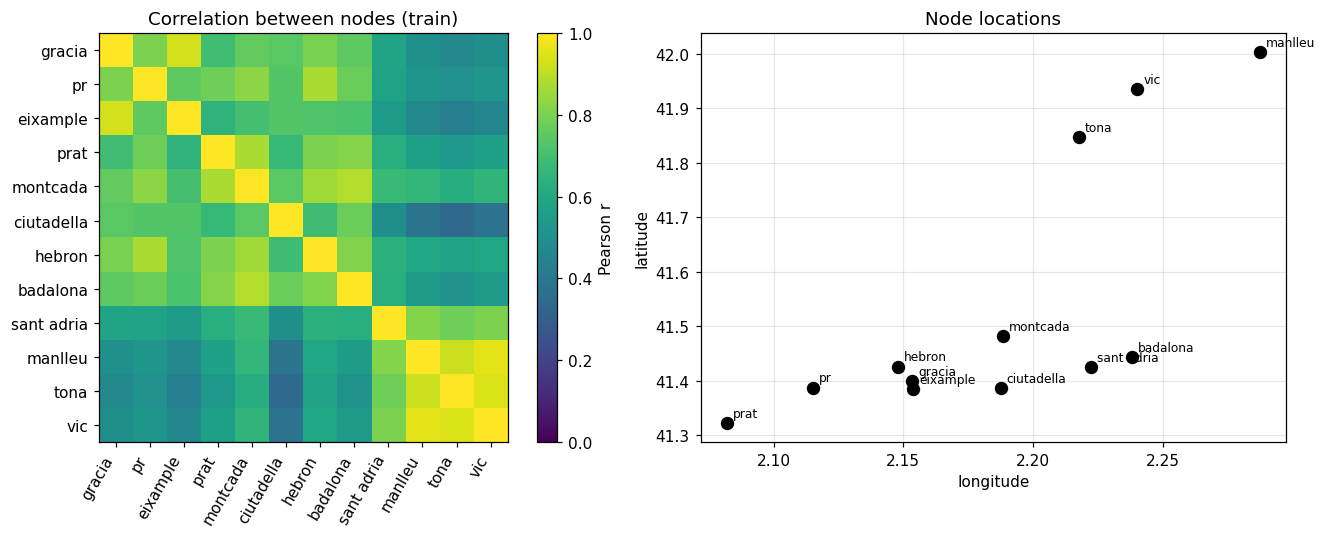

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
C = train.corr()
im = axes[0].imshow(C, cmap="viridis", vmin=0, vmax=1)
axes[0].set_xticks(range(N), nodes, rotation=60, ha="right"); axes[0].set_yticks(range(N), nodes)
axes[0].grid(False); plt.colorbar(im, ax=axes[0], fraction=0.046, label="Pearson r")
axes[0].set_title("Correlation between nodes (train)")
axes[1].scatter(loc["Lon"], loc["Lat"], s=60, color="k", zorder=3)
for n in nodes:
    axes[1].annotate(n, (loc.loc[n, "Lon"], loc.loc[n, "Lat"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
axes[1].set(xlabel="longitude", ylabel="latitude", title="Node locations")
fig.tight_layout(); fig.savefig(FIG / "1_4_overview.pdf", bbox_inches="tight"); plt.show()

### Helper: draw a graph on the map

In [4]:
lon, lat = loc["Lon"].to_numpy(), loc["Lat"].to_numpy()

def n_edges(W, tol=1e-4):
    A = np.abs(W) > tol; np.fill_diagonal(A, False)
    return int(A.sum() // 2)

def draw_graph(W, ax, title, color, tol=1e-4):
    A = np.abs(W.copy()); np.fill_diagonal(A, 0)
    wmax = A.max() if A.max() > 0 else 1
    for i in range(N):
        for j in range(i + 1, N):
            if A[i, j] > tol:
                ax.plot([lon[i], lon[j]], [lat[i], lat[j]], color=color, lw=0.5 + 3 * A[i, j] / wmax, alpha=0.7)
    ax.scatter(lon, lat, s=40, color="k", zorder=3)
    for i, n in enumerate(nodes):
        ax.annotate(n, (lon[i], lat[i]), xytext=(3, 3), textcoords="offset points", fontsize=7)
    ax.set_title(f"{title} — {n_edges(W, tol)} links", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

### (i) Distance-based graph

Haversine distance $d_{ij}$ (km) and Gaussian RBF weights
$w_{ij}=\exp\!\big(-d_{ij}^2/(2\theta^2)\big)$ if $d_{ij}<T$, $0$ otherwise.

With the threshold on the *distance* (as in the brief), the number of links depends **only on $T$**; $\theta$ only changes the
weights. To see the effect of $\theta$ on sparsity we also show the equivalent rule that prunes on the *weight*
($w_{ij}\ge\epsilon$), which is a distance threshold $T=\theta\sqrt{2\ln(1/\epsilon)}$ that grows with $\theta$.

            gracia    pr  eixample  prat  montcada  ciutadella  hebron  \
gracia         0.0   3.4       1.5  10.4       9.7         3.1     3.1   
pr             3.4   0.0       3.2   7.8      12.1         6.0     5.1   
eixample       1.5   3.2       0.0   9.3      11.1         2.8     4.6   
prat          10.4   7.8       9.3   0.0      19.9        11.4    12.8   
montcada       9.7  12.1      11.1  19.9       0.0        10.6     7.1   
ciutadella     3.1   6.0       2.8  11.4      10.6         0.0     5.5   
hebron         3.1   5.1       4.6  12.8       7.1         5.5     0.0   
badalona       8.7  12.0       9.6  18.8       5.9         7.7     7.8   
sant adria     6.5   9.9       7.3  16.4       6.9         5.2     6.2   
manlleu       68.1  70.0      69.6  77.7      58.5        69.1    65.2   
tona          50.1  51.8      51.6  59.4      40.6        51.2    47.1   
vic           60.1  61.8      61.5  69.4      50.6        61.2    57.1   

            badalona  sant adria  man

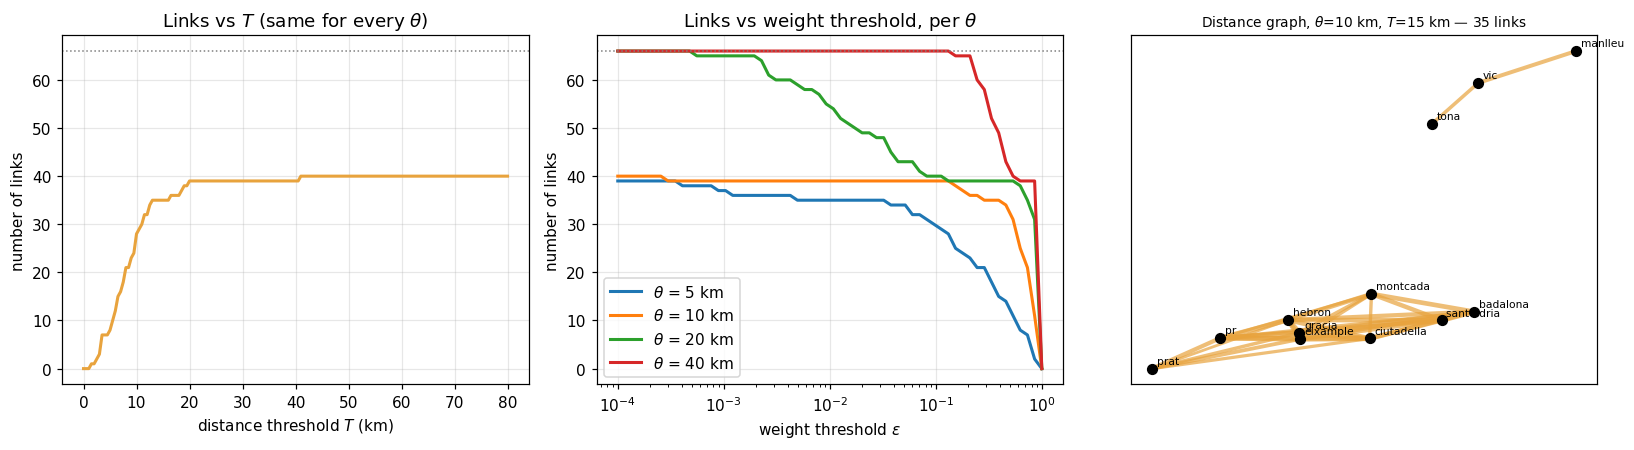

In [5]:
def haversine_matrix(lat, lon, R=6371.0):
    la, lo = np.radians(lat)[:, None], np.radians(lon)[:, None]
    a = np.sin((la - la.T) / 2) ** 2 + np.cos(la) * np.cos(la.T) * np.sin((lo - lo.T) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

Dkm = haversine_matrix(lat, lon)
print(pd.DataFrame(Dkm, index=nodes, columns=nodes).round(1))

def distance_graph(theta, T):
    W = np.exp(-Dkm**2 / (2 * theta**2)) * (Dkm < T)
    np.fill_diagonal(W, 0); return W

Ts = np.linspace(0, 80, 161)
thetas = [5, 10, 20, 40]
eps = np.logspace(-4, 0, 60)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].plot(Ts, [n_edges(distance_graph(10, T)) for T in Ts], color=MCOL["Distance"], lw=2)
axes[0].set(xlabel="distance threshold $T$ (km)", ylabel="number of links", title="Links vs $T$ (same for every $\\theta$)")
for th in thetas:
    axes[1].semilogx(eps, [n_edges(np.exp(-Dkm**2 / (2 * th**2)) * (np.exp(-Dkm**2 / (2 * th**2)) >= e) - np.eye(N)) for e in eps],
                     lw=2, label=f"$\\theta$ = {th} km")
axes[1].set(xlabel="weight threshold $\\epsilon$", ylabel="number of links", title="Links vs weight threshold, per $\\theta$")
axes[1].legend()
for ax in axes[:2]: ax.axhline(66, color="grey", ls=":", lw=1)
draw_graph(distance_graph(10, 15), axes[2], "Distance graph, $\\theta$=10 km, $T$=15 km", MCOL["Distance"])
fig.tight_layout(); fig.savefig(FIG / "1_4_distance.pdf", bbox_inches="tight"); plt.show()

### (ii) GLASSO

`sklearn.covariance.GraphicalLasso` on the standardised training data; $W=|\hat\Theta|$ off-diagonal, links where $|\hat\Theta_{ij}|>T$.

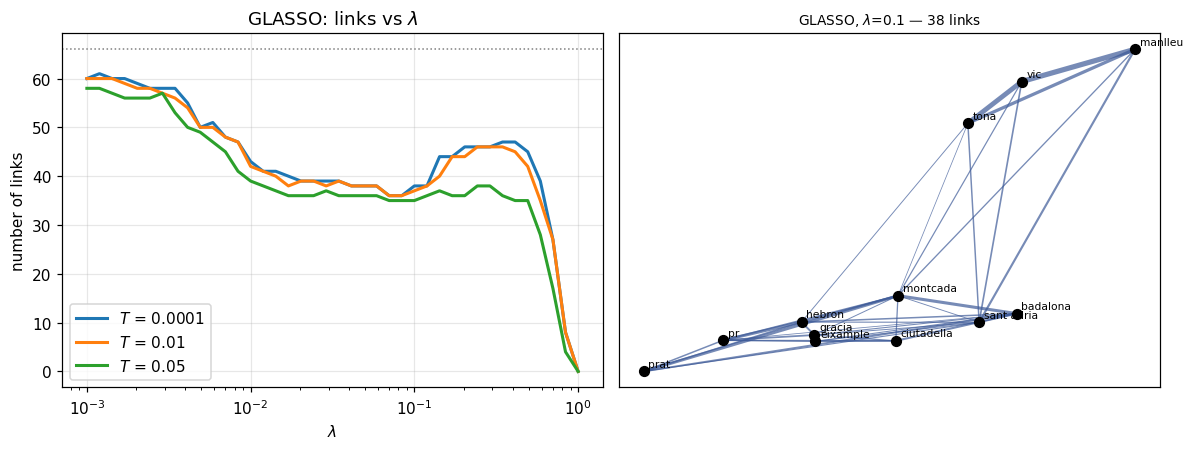

In [6]:
def glasso_graph(lam, T=1e-4):
    gl = GraphicalLasso(alpha=lam, max_iter=500, tol=1e-4).fit(Xtr)
    P = gl.precision_.copy(); np.fill_diagonal(P, 0)
    P[np.abs(P) <= T] = 0
    return P

lams = np.logspace(-3, 0, 40)
gl_edges = {T: [] for T in [1e-4, 1e-2, 5e-2]}
for lam in lams:
    gl = GraphicalLasso(alpha=lam, max_iter=500, tol=1e-4).fit(Xtr)
    P = gl.precision_.copy(); np.fill_diagonal(P, 0)
    for T in gl_edges:
        gl_edges[T].append(n_edges(np.where(np.abs(P) > T, P, 0)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for T, e in gl_edges.items():
    axes[0].semilogx(lams, e, lw=2, label=f"$T$ = {T:g}")
axes[0].axhline(66, color="grey", ls=":", lw=1)
axes[0].set(xlabel="$\\lambda$", ylabel="number of links", title="GLASSO: links vs $\\lambda$")
axes[0].legend()
draw_graph(glasso_graph(0.1), axes[1], "GLASSO, $\\lambda$=0.1", MCOL["GLASSO"])
fig.tight_layout(); fig.savefig(FIG / "1_4_glasso.pdf", bbox_inches="tight"); plt.show()

### (iii) Laplacian learning (Dong et al.)

$$\min_{\mathbf L,\mathbf Y}\ \|\mathbf X-\mathbf Y\|_F^2+\alpha\,\mathrm{tr}(\mathbf Y^\top\mathbf L\mathbf Y)+\beta\|\mathbf L\|_F^2
\quad\text{s.t.}\ \mathrm{tr}(\mathbf L)=N,\ L_{ij}=L_{ji}\le0\ (i\ne j),\ \mathbf L\mathbf 1=\mathbf 0$$

Here $\mathbf X\in\mathbb R^{N\times M}$ (nodes × samples). Alternating minimisation:
- **L-step** (convex QP, cvxpy): with $\mathbf Y$ fixed, $\mathrm{tr}(\mathbf Y^\top\mathbf L\mathbf Y)=\mathrm{tr}(\mathbf L\,\mathbf Y\mathbf Y^\top)$ is linear in $\mathbf L$.
- **Y-step** (closed form): $\mathbf Y=(\mathbf I+\alpha\mathbf L)^{-1}\mathbf X$.

$\mathbf X$ is standardised and the quadratic term is divided by $M$ so that $\alpha,\beta$ are independent of the number of samples.
Note that in the first L-step ($\mathbf Y=\mathbf X$) only the ratio $\beta/\alpha$ matters.

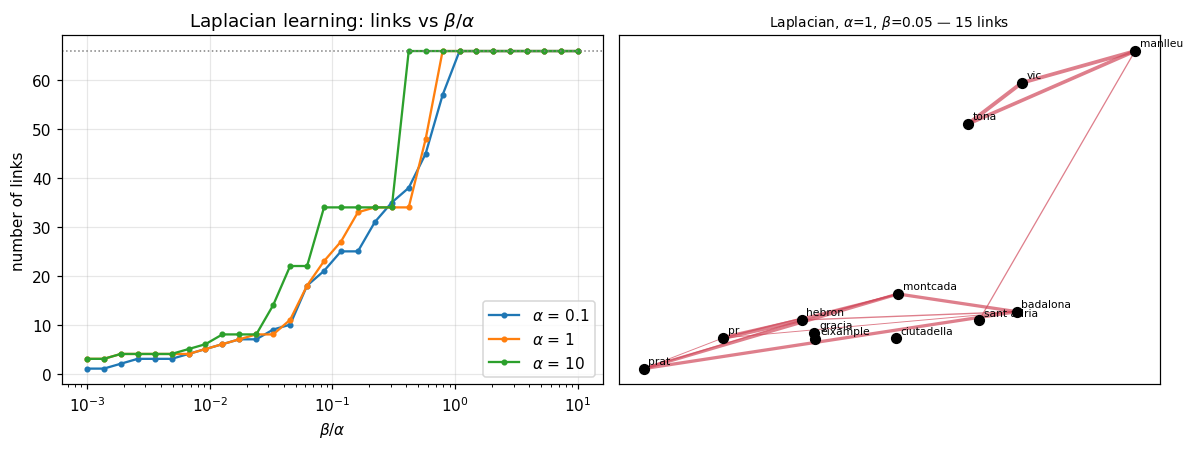

In [7]:
def laplacian_step(S, alpha, beta):
    L = cp.Variable((N, N), symmetric=True)
    obj = cp.Minimize(alpha * cp.trace(L @ S) + beta * cp.sum_squares(L))
    off = ~np.eye(N, dtype=bool)
    cons = [cp.trace(L) == N, L @ np.ones(N) == 0, L[off] <= 0]
    cp.Problem(obj, cons).solve(solver=cp.CLARABEL)
    Lv = L.value.copy(); Lv[np.abs(Lv) < 1e-5] = 0
    return Lv

def learn_laplacian(X, alpha, beta, n_iter=3):
    """X: N x M. Returns L and the smoothed Y."""
    Y = X.copy(); M = X.shape[1]
    for _ in range(n_iter):
        L = laplacian_step(Y @ Y.T / M, alpha, beta)
        Y = np.linalg.solve(np.eye(N) + alpha * L, X)
    return L, Y

XT = Xtr.T   # N x M

def lap_edges(L, tol=1e-4):
    W = -L.copy(); np.fill_diagonal(W, 0); return n_edges(W, tol)

ratios = np.logspace(-3, 1, 30)
lap_curves = {}
for a in [0.1, 1.0, 10.0]:
    lap_curves[a] = [lap_edges(learn_laplacian(XT, a, r * a)[0]) for r in ratios]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for a, e in lap_curves.items():
    axes[0].semilogx(ratios, e, "o-", ms=3, lw=1.5, label=f"$\\alpha$ = {a:g}")
axes[0].axhline(66, color="grey", ls=":", lw=1)
axes[0].set(xlabel="$\\beta/\\alpha$", ylabel="number of links", title="Laplacian learning: links vs $\\beta/\\alpha$")
axes[0].legend()
L_ex, _ = learn_laplacian(XT, 1.0, 0.05)
draw_graph(-L_ex + np.diag(np.diag(L_ex)), axes[1], "Laplacian, $\\alpha$=1, $\\beta$=0.05", MCOL["Laplacian"])
fig.tight_layout(); fig.savefig(FIG / "1_4_laplacian.pdf", bbox_inches="tight"); plt.show()

### Choosing sparse / medium / dense graphs

For a fair comparison between the three methods, each one is tuned to give roughly the same number of links:
~12 (sparse, mean degree 2), ~24 (medium, degree 4) and ~40 (dense, degree ≈ 6.7).

In [8]:
targets_links = {"sparse": 12, "medium": 24, "dense": 40}

def pick(builder, grid, target):
    cands = [(abs(n_edges(W) - target), p, W) for p in grid for W in [builder(p)]]
    _, p, W = min(cands, key=lambda c: (c[0], c[1]))
    return p, W

graphs = {}
for lvl, t in targets_links.items():
    p, W = pick(lambda T: distance_graph(10, T), np.linspace(1, 80, 160), t)
    graphs[("Distance", lvl)] = (f"T={p:.1f} km", W)
    p, W = pick(glasso_graph, np.logspace(-3, 0, 60), t)
    graphs[("GLASSO", lvl)] = (f"λ={p:.3g}", W)
    p, W = pick(lambda r: -(lambda L: L - np.diag(np.diag(L)))(learn_laplacian(XT, 1.0, r)[0]), np.logspace(-3, 1, 50), t)
    graphs[("Laplacian", lvl)] = (f"α=1, β={p:.3g}", W)

pd.DataFrame({k: {"param": v[0], "links": n_edges(v[1])} for k, v in graphs.items()}).T

,,param,links
Distance,sparse,T=6.0 km,12
GLASSO,sparse,λ=0.791,16
Laplacian,sparse,"α=1, β=0.0429",9
Distance,medium,T=9.4 km,24
GLASSO,medium,λ=0.704,27
Laplacian,medium,"α=1, β=0.11",24
Distance,dense,T=40.7 km,40
GLASSO,dense,λ=0.0166,40
Laplacian,dense,"α=1, β=0.494",38


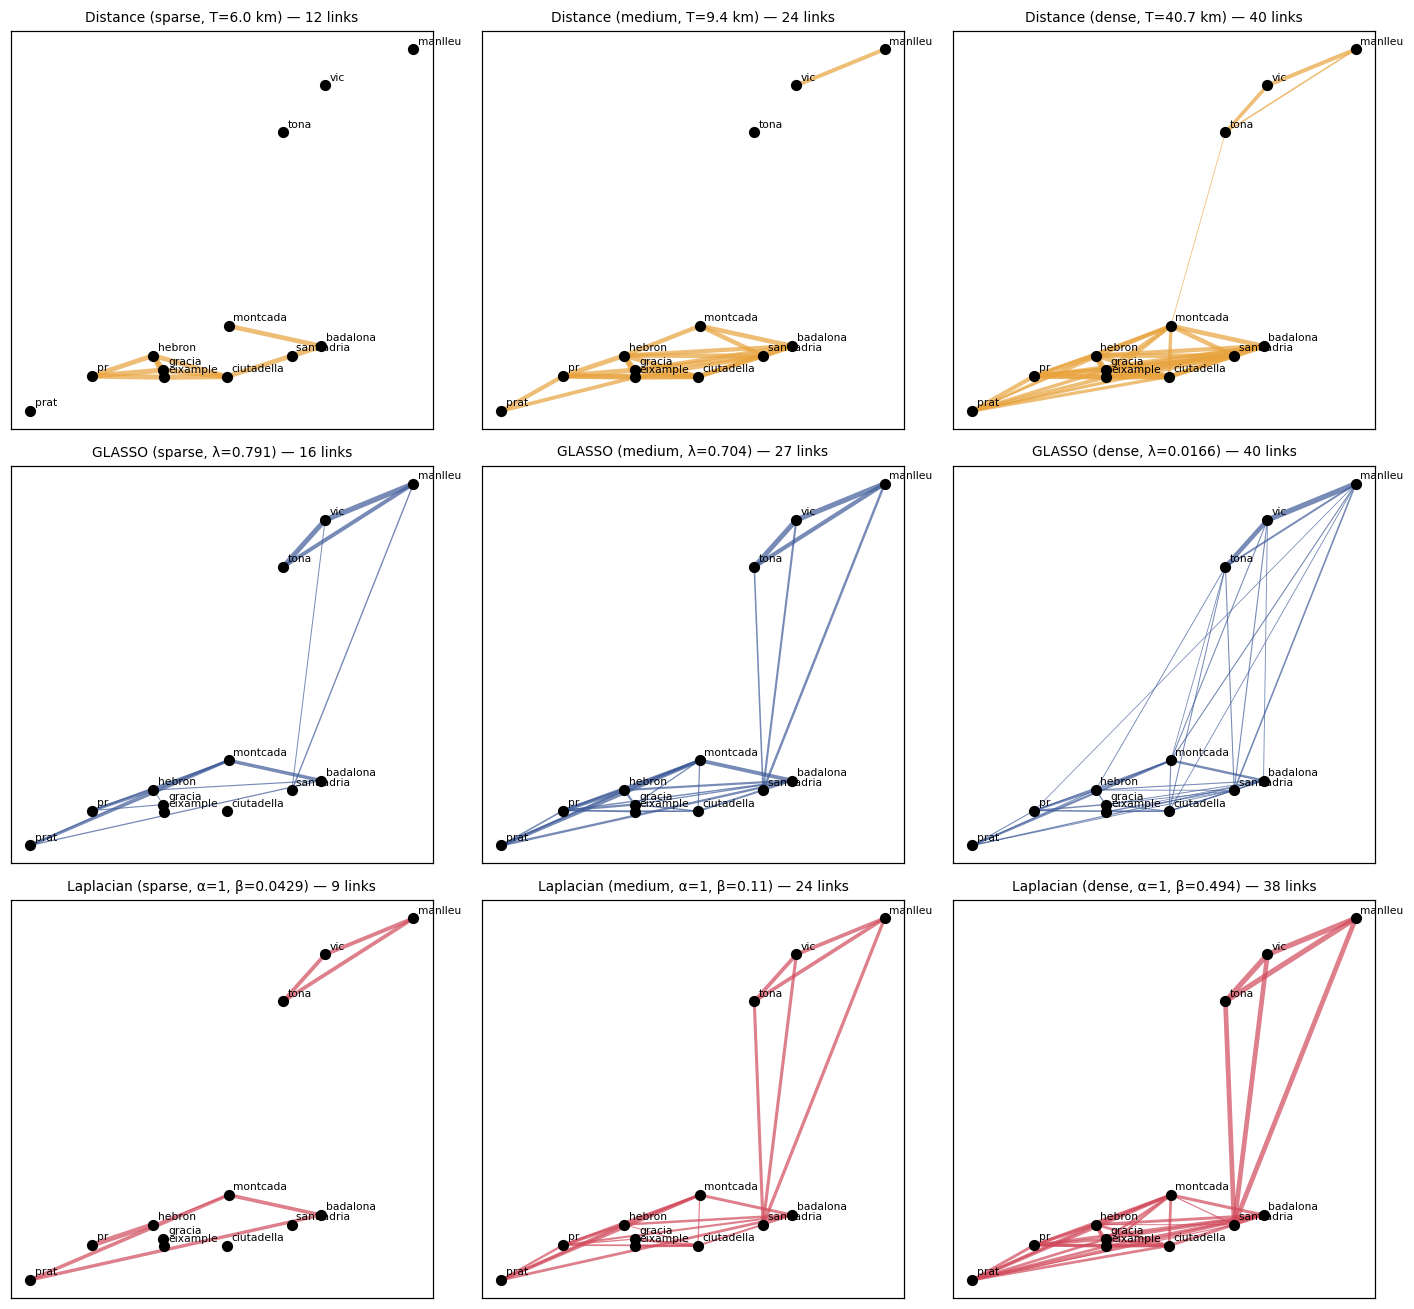

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for r, m in enumerate(["Distance", "GLASSO", "Laplacian"]):
    for c, lvl in enumerate(targets_links):
        par, W = graphs[(m, lvl)]
        draw_graph(W, axes[r, c], f"{m} ({lvl}, {par})", MCOL[m])
fig.tight_layout(); fig.savefig(FIG / "1_4_graphs_grid.pdf", bbox_inches="tight"); plt.show()

### Virtual sensors

For each target node $k$, the features are its neighbours in the graph (non-zero $W_{kj}$). Models:
- **MLR** (ordinary least squares),
- **SVR** with RBF kernel ($C$ tuned by 3-fold time-series CV on the training set),
- **Full mesh** baselines: MLR, Ridge and Lasso on all 11 other nodes (regularisation chosen by time-series CV).

A node without neighbours cannot be reconstructed from the graph; it is predicted with the training mean and flagged.

In [10]:
tscv = TimeSeriesSplit(n_splits=3)

def fit_predict(model, feats, tgt):
    if len(feats) == 0:
        return np.full(len(test), train[tgt].mean())
    if model == "MLR":
        est = make_pipeline(StandardScaler(), LinearRegression())
    elif model == "SVR":
        est = GridSearchCV(make_pipeline(StandardScaler(), SVR(kernel="rbf", epsilon=1.0)),
                           {"svr__C": [1, 10, 100], "svr__gamma": ["scale"]}, cv=tscv, scoring="neg_root_mean_squared_error")
    elif model == "Ridge":
        est = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 25), cv=tscv))
    elif model == "Lasso":
        est = make_pipeline(StandardScaler(), LassoCV(cv=tscv, max_iter=20000))
    est.fit(train[feats], train[tgt])
    return est.predict(test[feats])

rows = []
for (m, lvl), (par, W) in graphs.items():
    for k, tgt in enumerate(nodes):
        feats = [nodes[j] for j in range(N) if j != k and abs(W[k, j]) > 1e-4]
        for model in ["MLR", "SVR"]:
            yhat = fit_predict(model, feats, tgt)
            rows.append(dict(graph=m, level=lvl, model=model, target=tgt, n_neigh=len(feats),
                             RMSE=np.sqrt(mean_squared_error(test[tgt], yhat)), R2=r2_score(test[tgt], yhat)))
for k, tgt in enumerate(nodes):
    feats = [n for n in nodes if n != tgt]
    for model in ["MLR", "Ridge", "Lasso", "SVR"]:
        yhat = fit_predict(model, feats, tgt)
        rows.append(dict(graph="Full mesh", level="full", model=model, target=tgt, n_neigh=len(feats),
                         RMSE=np.sqrt(mean_squared_error(test[tgt], yhat)), R2=r2_score(test[tgt], yhat)))
res = pd.DataFrame(rows)
res.to_csv("results_1_4_virtual_sensors.csv", index=False)
print("Targets without neighbours:\n", res[res.n_neigh == 0].groupby(["graph", "level"]).target.unique())

Targets without neighbours:
 graph      level 
Distance   medium                        [tona]
           sparse    [prat, manlleu, tona, vic]
GLASSO     sparse                  [ciutadella]
Laplacian  sparse      [ciutadella, sant adria]
Name: target, dtype: object


In [11]:
summary = (res.groupby(["graph", "level", "model"])
              .agg(mean_RMSE=("RMSE", "mean"), mean_R2=("R2", "mean"), median_R2=("R2", "median"),
                   mean_neigh=("n_neigh", "mean"), isolated=("n_neigh", lambda s: int((s == 0).sum())))
              .round(3))
summary

mean_RMSE  mean_R2  median_R2  mean_neigh  isolated
graph     level  model                                                     
Distance  dense  MLR       12.168    0.784      0.796       6.667         0
                 SVR       12.263    0.781      0.772       6.667         0
          medium MLR       15.234    0.657      0.763       4.000         1
                 SVR       15.124    0.662      0.755       4.000         1
          sparse MLR       21.529    0.376      0.637       2.000         4
                 SVR       21.348    0.382      0.648       2.000         4
Full mesh full   Lasso     11.596    0.806      0.799      11.000         0
                 MLR       11.685    0.802      0.796      11.000         0
                 Ridge     11.666    0.803      0.799      11.000         0
                 SVR       12.111    0.793      0.769      11.000         0
GLASSO    dense  MLR       11.614    0.805      0.803       6.667         0
                 SVR       11.815    0.800      0.788       6.667         0
          medium MLR       11.821    0.798      0.802       4.500         0
                 SVR       11.621    0.805      0.781       4.500         0
          sparse MLR       12.871    0.734      0.793       2.667         1
                 SVR       12.679    0.740      0.786       2.667         1
Laplacian dense  MLR       11.666    0.803      0.796       6.333         0
                 SVR       11.763    0.801      0.772       6.333         0
          medium MLR       11.845    0.798      0.794       4.000         0
                 SVR       11.657    0.804      0.779       4.000         0
          sparse MLR       14.431    0.657      0.764       1.500         2
                 SVR       14.395    0.657      0.758       1.500         2

### Comparison across graph methods and densities

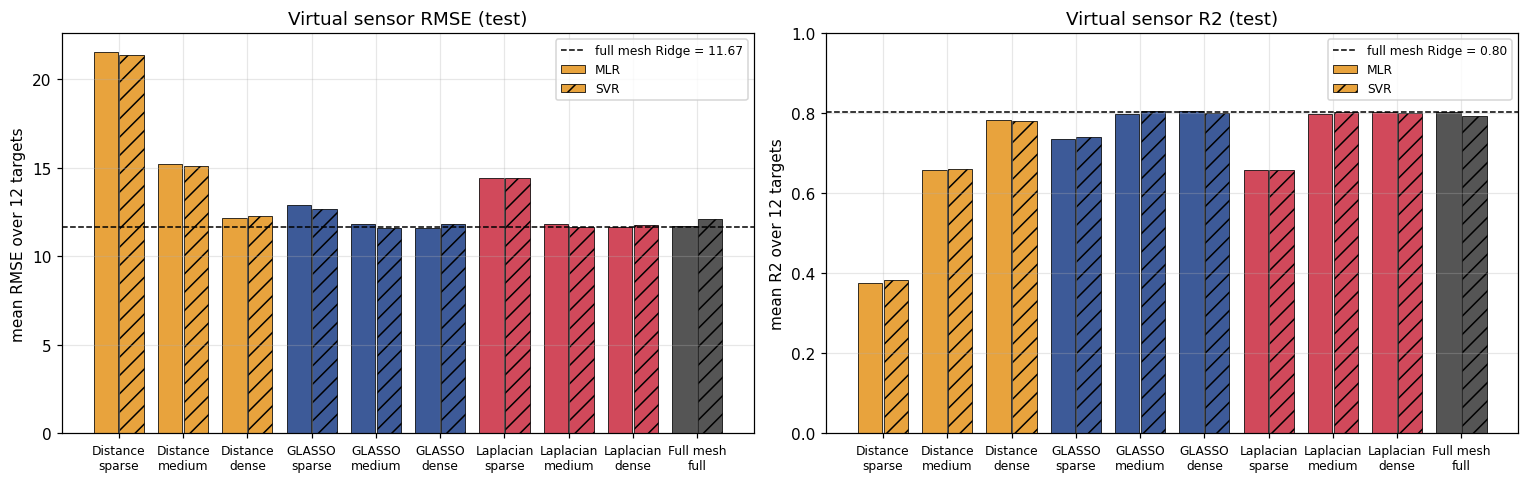

In [12]:
order = [("Distance", l) for l in targets_links] + [("GLASSO", l) for l in targets_links] + \
        [("Laplacian", l) for l in targets_links] + [("Full mesh", "full")]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=False)
for ax, metric in zip(axes, ["RMSE", "R2"]):
    labels, x = [], np.arange(len(order))
    for off, model, hatch in [(-0.2, "MLR", ""), (0.2, "SVR", "//")]:
        vals = [res[(res.graph == g) & (res.level == l) & (res.model == model)][metric].mean() for g, l in order]
        ax.bar(x + off, vals, width=0.38, color=[MCOL[g] for g, _ in order], hatch=hatch, edgecolor="k", lw=0.5,
               label=model)
    ridge = res[(res.graph == "Full mesh") & (res.model == "Ridge")][metric].mean()
    ax.axhline(ridge, color="k", ls="--", lw=1, label=f"full mesh Ridge = {ridge:.2f}")
    ax.set_xticks(x, [f"{g}\n{l}" for g, l in order], fontsize=8)
    ax.set(ylabel=f"mean {metric} over 12 targets", title=f"Virtual sensor {metric} (test)")
    ax.legend(fontsize=8)
axes[1].set_ylim(0, 1)
fig.tight_layout(); fig.savefig(FIG / "1_4_vs_summary.pdf", bbox_inches="tight"); plt.show()

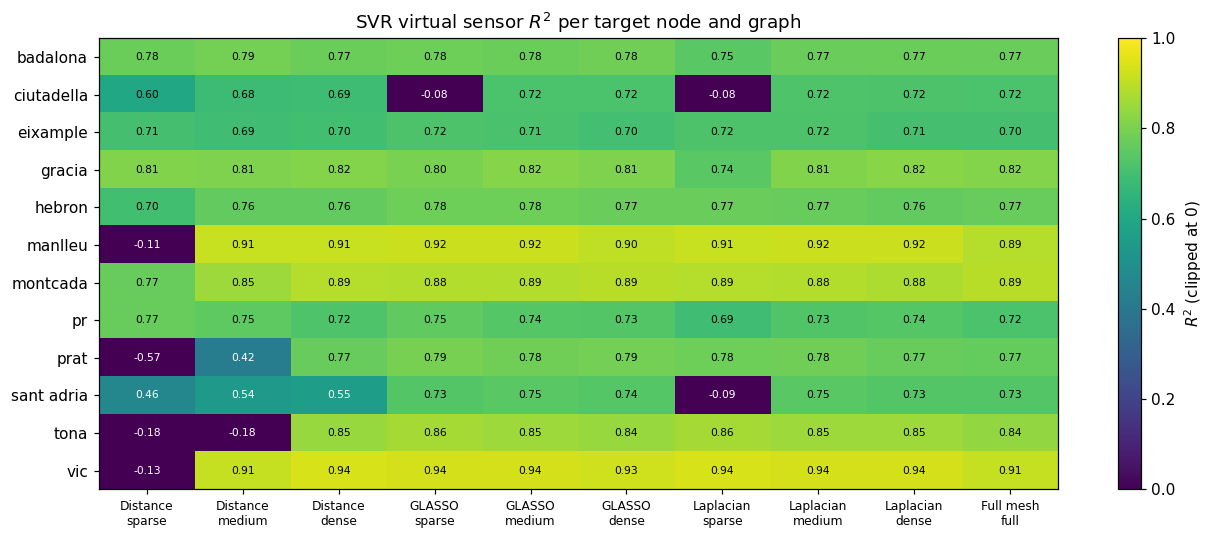

In [13]:
piv = res[res.model == "SVR"].pivot_table(index="target", columns=["graph", "level"], values="R2")
piv = piv[[c for c in order if c in piv.columns]]
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(piv.clip(lower=0), cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(piv.shape[1]), [f"{g}\n{l}" for g, l in piv.columns], fontsize=8)
ax.set_yticks(range(N), piv.index); ax.grid(False)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        ax.text(j, i, f"{piv.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="w" if piv.iloc[i, j] < 0.6 else "k")
plt.colorbar(im, ax=ax, label="$R^2$ (clipped at 0)")
ax.set_title("SVR virtual sensor $R^2$ per target node and graph")
fig.tight_layout(); fig.savefig(FIG / "1_4_vs_heatmap.pdf", bbox_inches="tight"); plt.show()

### Example reconstruction

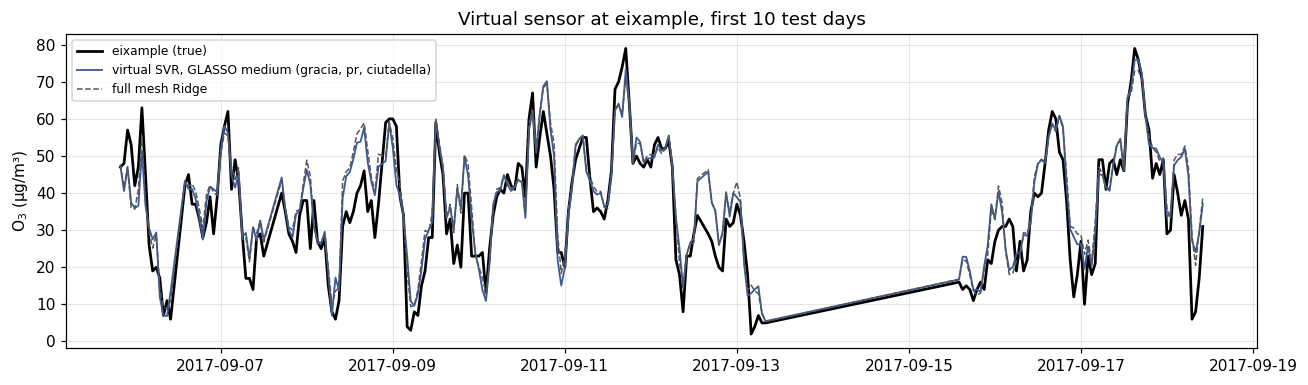

In [14]:
ex_tgt = "eixample"
par, W = graphs[("GLASSO", "medium")]
k = nodes.index(ex_tgt)
feats = [nodes[j] for j in range(N) if j != k and abs(W[k, j]) > 1e-4]
yhat = fit_predict("SVR", feats, ex_tgt)
yfull = fit_predict("Ridge", [n for n in nodes if n != ex_tgt], ex_tgt)
win = slice(0, 24 * 10)
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(test.index[win], test[ex_tgt].iloc[win], color="k", lw=1.8, label=f"{ex_tgt} (true)")
ax.plot(test.index[win], yhat[win], color=MCOL["GLASSO"], lw=1.2, label=f"virtual SVR, GLASSO medium ({', '.join(feats)})")
ax.plot(test.index[win], yfull[win], color=MCOL["Full mesh"], lw=1, ls="--", label="full mesh Ridge")
ax.set(ylabel="O$_3$ (µg/m³)", title=f"Virtual sensor at {ex_tgt}, first 10 test days")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "1_4_vs_example.pdf", bbox_inches="tight"); plt.show()

### Observations (draft, to refine)

- The distance graph splits into a Barcelona metropolitan cluster and a northern cluster (Vic, Tona, Manlleu, ~50–70 km away);
  it ignores that nearby sites can behave differently (traffic vs background stations).
- GLASSO and the Laplacian learn links from the data: they connect nodes with similar O$_3$ dynamics, which can be far apart.
- Sparsity: distance → $T$ only; GLASSO → $\lambda$ (monotone decreasing); Laplacian → $\beta/\alpha$ (small ratio → sparse).
- Virtual sensors: compare data-driven vs distance-driven neighbourhoods, sparse vs dense, and against the full mesh (with/without regularisation).